In [1]:
import pandas as pd

In [7]:
#1
from pathlib import Path

PROJECT_PATH = Path(
    r"C:\Users\vicky\OneDrive\Desktop\PROJECTS\Healthcare_Cost_Optimization_Analytics"
)

print(PROJECT_PATH)

C:\Users\vicky\OneDrive\Desktop\PROJECTS\Healthcare_Cost_Optimization_Analytics


In [9]:
#1
analytical_path = PROJECT_PATH / "data" / "Analytical_Dataset" / "healthcare_analytical_dataset.csv"

master = pd.read_csv(analytical_path)

print("Analytical dataset loaded successfully.")
print("Rows:", len(master))
print("Columns:", len(master.columns))

Analytical dataset loaded successfully.
Rows: 61459
Columns: 58


In [4]:
#1
print("========== DATASET OVERVIEW ==========")
print("Shape:", master.shape)
print("\nColumns:")
print(master.columns.tolist())

========== DATASET OVERVIEW ==========
Shape: (61459, 58)

Columns:
['Id', 'START', 'STOP', 'PATIENT', 'PROVIDER', 'PAYER', 'ENCOUNTERCLASS', 'CODE', 'DESCRIPTION', 'BASE_ENCOUNTER_COST', 'TOTAL_CLAIM_COST', 'PAYER_COVERAGE', 'REASONCODE', 'REASONDESCRIPTION', 'BIRTHDATE', 'PATIENT_GENDER', 'RACE', 'ETHNICITY', 'MARITAL', 'AGE_AT_ENCOUNTER', 'condition_count', 'procedure_count', 'procedure_cost', 'medication_count', 'medication_cost', 'immunization_count', 'immunization_cost', 'observation_count', 'allergy_count', 'careplan_count', 'device_count', 'imaging_study_count', 'supply_count', 'supply_quantity', 'PROVIDER_GENDER', 'PROVIDER_ORGANIZATION', 'GENDER', 'PROVIDER_SPECIALITY', 'PROVIDER_UTILIZATION', 'ORGANIZATION_NAME', 'ORGANIZATION_CITY', 'ORGANIZATION_STATE', 'ORGANIZATION_UTILIZATION', 'PAYER_NAME', 'PAYER_AMOUNT_COVERED', 'PAYER_AMOUNT_UNCOVERED', 'PAYER_QOLS_AVG', 'PAYER_MEMBER_MONTHS', 'claim_count', 'billed_claim_count', 'closed_claim_count', 'transaction_charge_amount', 't

In [5]:
#1
cost_summary = master["TOTAL_CLAIM_COST"].describe()

print("========== OVERALL HEALTHCARE COST SUMMARY ==========")
print(cost_summary)

========== OVERALL HEALTHCARE COST SUMMARY ==========
count     61459.000000
mean       4149.657952
std       10919.677889
min           0.000000
25%         129.160000
50%         786.330000
75%        1625.890000
max      873646.190000
Name: TOTAL_CLAIM_COST, dtype: float64


In [6]:
#1
zero_cost_count = (master["TOTAL_CLAIM_COST"] == 0).sum()
positive_cost_count = (master["TOTAL_CLAIM_COST"] > 0).sum()

print("========== ZERO VS POSITIVE COST ==========")
print("Zero-cost encounters:", zero_cost_count)
print("Positive-cost encounters:", positive_cost_count)
print("Total encounters:", len(master))

========== ZERO VS POSITIVE COST ==========
Zero-cost encounters: 229
Positive-cost encounters: 61230
Total encounters: 61459


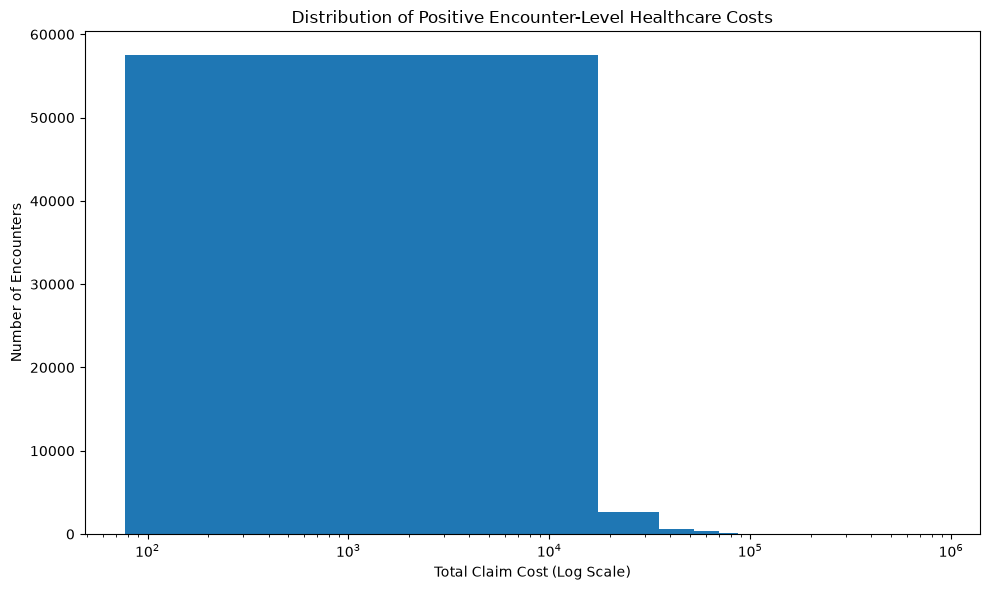

In [10]:
import matplotlib.pyplot as plt

# Positive costs only for log-scale visualization
positive_costs = master.loc[
    master["TOTAL_CLAIM_COST"] > 0,
    "TOTAL_CLAIM_COST"
]

plt.figure(figsize=(10, 6))

plt.hist(positive_costs, bins=50)

plt.xscale("log")

plt.xlabel("Total Claim Cost (Log Scale)")
plt.ylabel("Number of Encounters")
plt.title("Distribution of Positive Encounter-Level Healthcare Costs")

plt.tight_layout()
plt.show()

In [11]:
# Identify the top 1% highest-cost encounters
cost_data = master["TOTAL_CLAIM_COST"].sort_values(ascending=False)

top_1_percent_count = int(len(master) * 0.01)

top_1_percent_cost = cost_data.head(top_1_percent_count).sum()
total_cost = cost_data.sum()

top_1_percent_share = (top_1_percent_cost / total_cost) * 100

print("========== TOP 1% COST CONCENTRATION ==========")
print("Total encounters:", len(master))
print("Top 1% encounters:", top_1_percent_count)
print("Top 1% total cost:", round(top_1_percent_cost, 2))
print("Overall total cost:", round(total_cost, 2))
print("Top 1% share of total cost:", round(top_1_percent_share, 2), "%")

========== TOP 1% COST CONCENTRATION ==========
Total encounters: 61459
Top 1% encounters: 614
Top 1% total cost: 43475903.75
Overall total cost: 255033828.08
Top 1% share of total cost: 17.05 %


In [12]:
# Q2 — Step 1: Healthcare Cost by Encounter Type

encounter_cost_summary = (
    master
    .groupby("ENCOUNTERCLASS")
    .agg(
        Encounter_Count=("Id", "count"),
        Total_Cost=("TOTAL_CLAIM_COST", "sum"),
        Average_Cost=("TOTAL_CLAIM_COST", "mean"),
        Median_Cost=("TOTAL_CLAIM_COST", "median")
    )
    .sort_values("Total_Cost", ascending=False)
)

encounter_cost_summary

,Encounter_Count,Total_Cost,Average_Cost,Median_Cost
ENCOUNTERCLASS,,,,
ambulatory,20124,1.312929e+08,6524.192984,645.810
wellness,24038,4.590036e+07,1909.491582,926.850
outpatient,10837,3.064173e+07,2827.510556,129.160
emergency,2168,1.718445e+07,7926.408824,645.810
inpatient,1728,1.514765e+07,8765.999421,6493.455
urgentcare,2564,1.486678e+07,5798.274797,129.160


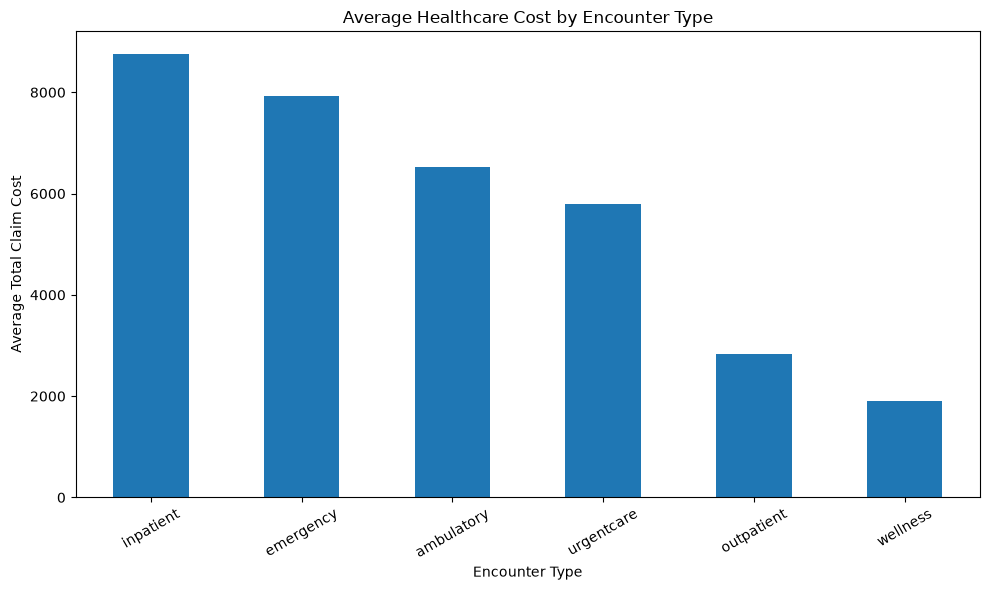

In [14]:
# Q2 — Step 2: Average Cost by Encounter Type

avg_cost_by_encounter = (
    master
    .groupby("ENCOUNTERCLASS")["TOTAL_CLAIM_COST"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

avg_cost_by_encounter.plot(kind="bar")

plt.xlabel("Encounter Type")
plt.ylabel("Average Total Claim Cost")
plt.title("Average Healthcare Cost by Encounter Type")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [15]:
# Q2 — Step 3: Cost Contribution by Encounter Type

encounter_cost_share = (
    master
    .groupby("ENCOUNTERCLASS")["TOTAL_CLAIM_COST"]
    .agg(
        Encounter_Count="count",
        Total_Cost="sum"
    )
)

encounter_cost_share["Cost_Share_Percent"] = (
    encounter_cost_share["Total_Cost"]
    / encounter_cost_share["Total_Cost"].sum()
    * 100
)

encounter_cost_share = encounter_cost_share.sort_values(
    "Cost_Share_Percent",
    ascending=False
)

encounter_cost_share

,Encounter_Count,Total_Cost,Cost_Share_Percent
ENCOUNTERCLASS,,,
ambulatory,20124,1.312929e+08,51.480567
wellness,24038,4.590036e+07,17.997753
outpatient,10837,3.064173e+07,12.014772
emergency,2168,1.718445e+07,6.738108
inpatient,1728,1.514765e+07,5.939466
urgentcare,2564,1.486678e+07,5.829335


In [16]:
# Q3 — Step 1: Healthcare Cost by Patient Gender

gender_cost_summary = (
    master
    .groupby("PATIENT_GENDER")
    .agg(
        Encounter_Count=("Id", "count"),
        Total_Cost=("TOTAL_CLAIM_COST", "sum"),
        Average_Cost=("TOTAL_CLAIM_COST", "mean"),
        Median_Cost=("TOTAL_CLAIM_COST", "median")
    )
    .sort_values("Total_Cost", ascending=False)
)

gender_cost_summary

,Encounter_Count,Total_Cost,Average_Cost,Median_Cost
PATIENT_GENDER,,,,
F,35533,1.566388e+08,4408.261907,786.33
M,25926,9.839506e+07,3795.227098,786.33


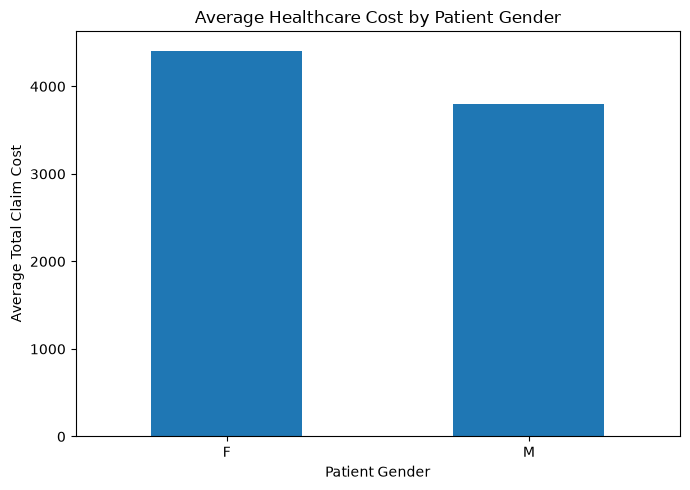

In [17]:
# Q3 — Step 1 Visualization: Average Cost by Gender

plt.figure(figsize=(7, 5))

gender_cost_summary["Average_Cost"].plot(kind="bar")

plt.xlabel("Patient Gender")
plt.ylabel("Average Total Claim Cost")
plt.title("Average Healthcare Cost by Patient Gender")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:
# Q3 — Step 2: Create Age Groups

age_bins = [0, 18, 35, 50, 65, 80, 120]
age_labels = ["0-18", "19-35", "36-50", "51-65", "66-80", "81+"]

master["AGE_GROUP"] = pd.cut(
    master["AGE_AT_ENCOUNTER"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

age_cost_summary = (
    master
    .groupby("AGE_GROUP", observed=False)
    .agg(
        Encounter_Count=("Id", "count"),
        Total_Cost=("TOTAL_CLAIM_COST", "sum"),
        Average_Cost=("TOTAL_CLAIM_COST", "mean"),
        Median_Cost=("TOTAL_CLAIM_COST", "median")
    )
)

age_cost_summary

,Encounter_Count,Total_Cost,Average_Cost,Median_Cost
AGE_GROUP,,,,
0-18,9810,35860717.15,3655.526723,786.330
19-35,15830,78759656.35,4975.341526,1108.045
36-50,11954,47205054.57,3948.891967,786.330
51-65,11467,30265639.52,2639.368581,645.810
66-80,8177,31305090.12,3828.432203,645.810
81+,4221,31637670.37,7495.302149,129.160


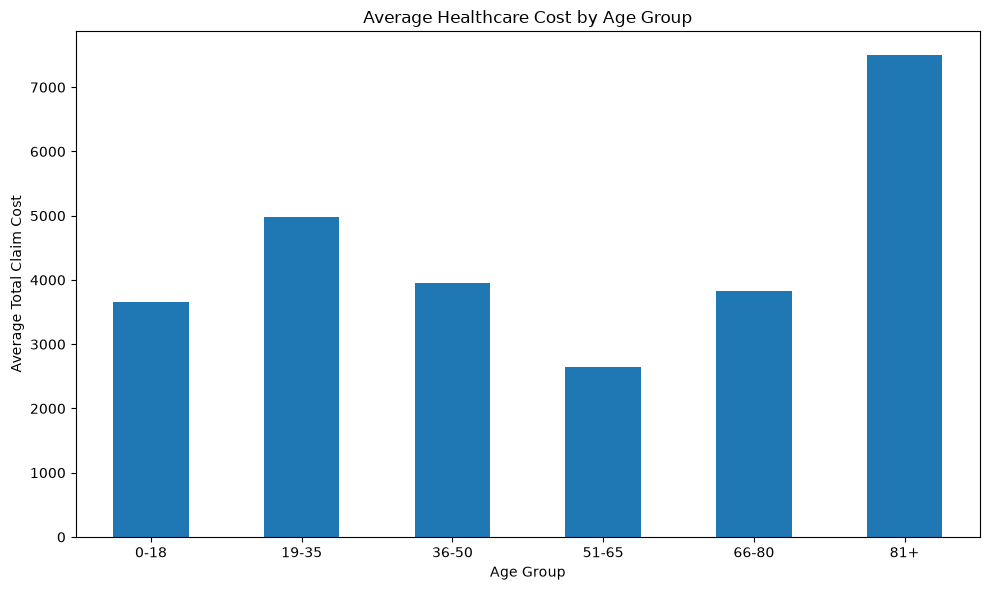

In [19]:
# Q3 — Step 2 Visualization: Average Cost by Age Group

plt.figure(figsize=(10, 6))

age_cost_summary["Average_Cost"].plot(kind="bar")

plt.xlabel("Age Group")
plt.ylabel("Average Total Claim Cost")
plt.title("Average Healthcare Cost by Age Group")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [20]:
# Q3 — Step 3: Healthcare Cost by Race

race_cost_summary = (
    master
    .groupby("RACE")
    .agg(
        Encounter_Count=("Id", "count"),
        Total_Cost=("TOTAL_CLAIM_COST", "sum"),
        Average_Cost=("TOTAL_CLAIM_COST", "mean"),
        Median_Cost=("TOTAL_CLAIM_COST", "median")
    )
    .sort_values("Total_Cost", ascending=False)
)

race_cost_summary

,Encounter_Count,Total_Cost,Average_Cost,Median_Cost
RACE,,,,
white,48857,1.906827e+08,3902.873834,786.33
black,6271,3.897376e+07,6214.919860,786.33
asian,5043,1.966215e+07,3898.900034,890.32
hawaiian,741,2.964769e+06,4001.037436,786.33
other,490,2.684946e+06,5479.481061,1067.37
native,57,6.549141e+04,1148.972105,786.33


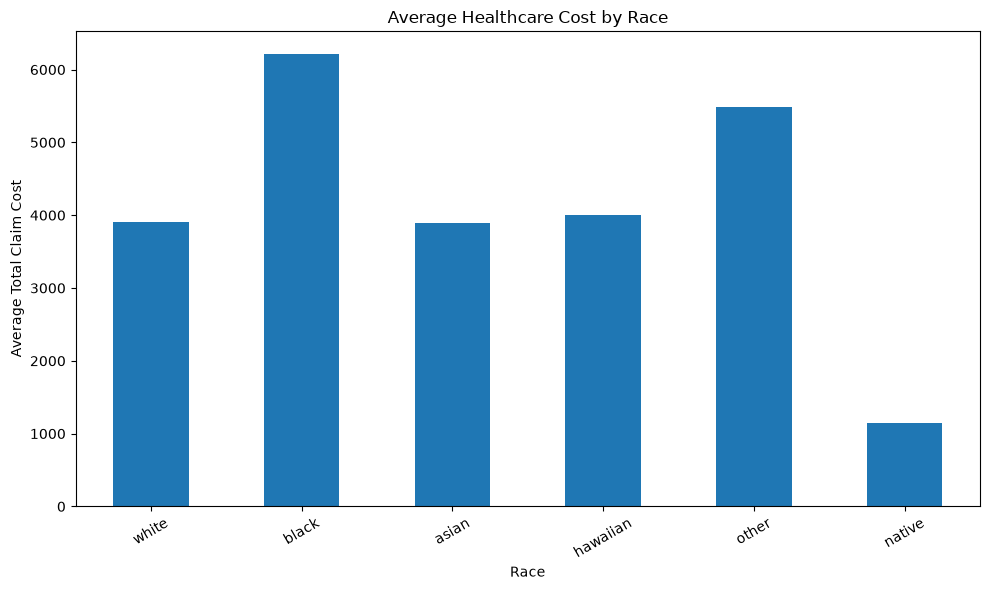

In [21]:
# Q3 — Step 3 Visualization: Average Cost by Race

plt.figure(figsize=(10, 6))

race_cost_summary["Average_Cost"].plot(kind="bar")

plt.xlabel("Race")
plt.ylabel("Average Total Claim Cost")
plt.title("Average Healthcare Cost by Race")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [22]:
# Q3 — Step 4: Healthcare Cost by Ethnicity

ethnicity_cost_summary = (
    master
    .groupby("ETHNICITY")
    .agg(
        Encounter_Count=("Id", "count"),
        Total_Cost=("TOTAL_CLAIM_COST", "sum"),
        Average_Cost=("TOTAL_CLAIM_COST", "mean"),
        Median_Cost=("TOTAL_CLAIM_COST", "median")
    )
    .sort_values("Total_Cost", ascending=False)
)

ethnicity_cost_summary

,Encounter_Count,Total_Cost,Average_Cost,Median_Cost
ETHNICITY,,,,
nonhispanic,57195,2.376967e+08,4155.900603,786.33
hispanic,4264,1.733709e+07,4065.922390,786.33


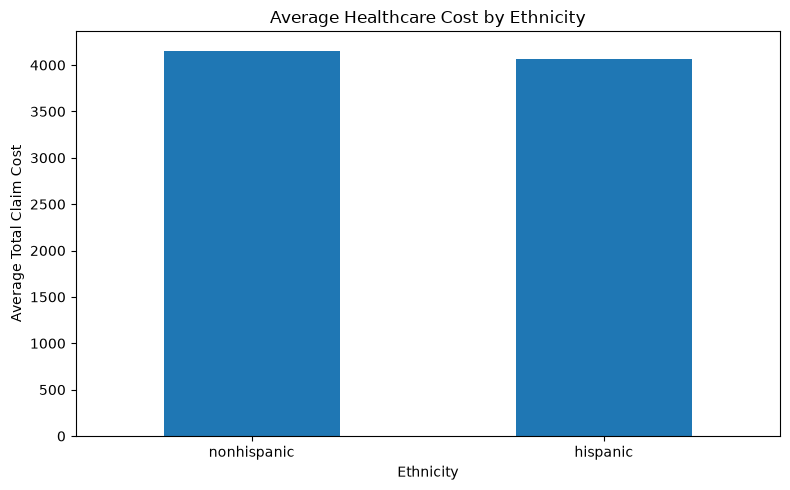

In [23]:
# Q3 — Step 4 Visualization: Average Cost by Ethnicity

plt.figure(figsize=(8, 5))

ethnicity_cost_summary["Average_Cost"].plot(kind="bar")

plt.xlabel("Ethnicity")
plt.ylabel("Average Total Claim Cost")
plt.title("Average Healthcare Cost by Ethnicity")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [24]:
# Q4 — Healthcare Utilization vs Cost
# Step 1: Summary of utilization measures

utilization_summary = master[
    [
        "condition_count",
        "procedure_count",
        "medication_count",
        "observation_count",
        "imaging_study_count",
        "careplan_count",
        "TOTAL_CLAIM_COST"
    ]
].describe().T

utilization_summary

,count,mean,std,min,25%,50%,75%,max
condition_count,61459.0,0.619828,0.861531,0.0,0.00,0.00,1.00,13.00
procedure_count,61459.0,1.363885,2.512788,0.0,0.00,0.00,1.00,27.00
medication_count,61459.0,0.918173,1.421406,0.0,0.00,0.00,1.00,13.00
observation_count,61459.0,8.123025,18.311008,0.0,0.00,0.00,9.00,678.00
imaging_study_count,61459.0,0.014969,0.121431,0.0,0.00,0.00,0.00,1.00
careplan_count,61459.0,0.063961,0.250079,0.0,0.00,0.00,0.00,2.00
TOTAL_CLAIM_COST,61459.0,4149.657952,10919.677889,0.0,129.16,786.33,1625.89,873646.19


In [25]:
# Q4 — Step 2: Correlation between utilization measures and healthcare cost

utilization_columns = [
    "condition_count",
    "procedure_count",
    "medication_count",
    "observation_count",
    "imaging_study_count",
    "careplan_count"
]

correlation_with_cost = (
    master[utilization_columns + ["TOTAL_CLAIM_COST"]]
    .corr()["TOTAL_CLAIM_COST"]
    .drop("TOTAL_CLAIM_COST")
    .sort_values(ascending=False)
)

correlation_with_cost

procedure_count        0.317238
careplan_count         0.112748
imaging_study_count    0.057567
medication_count       0.048055
observation_count     -0.004210
condition_count       -0.015844
Name: TOTAL_CLAIM_COST, dtype: float64

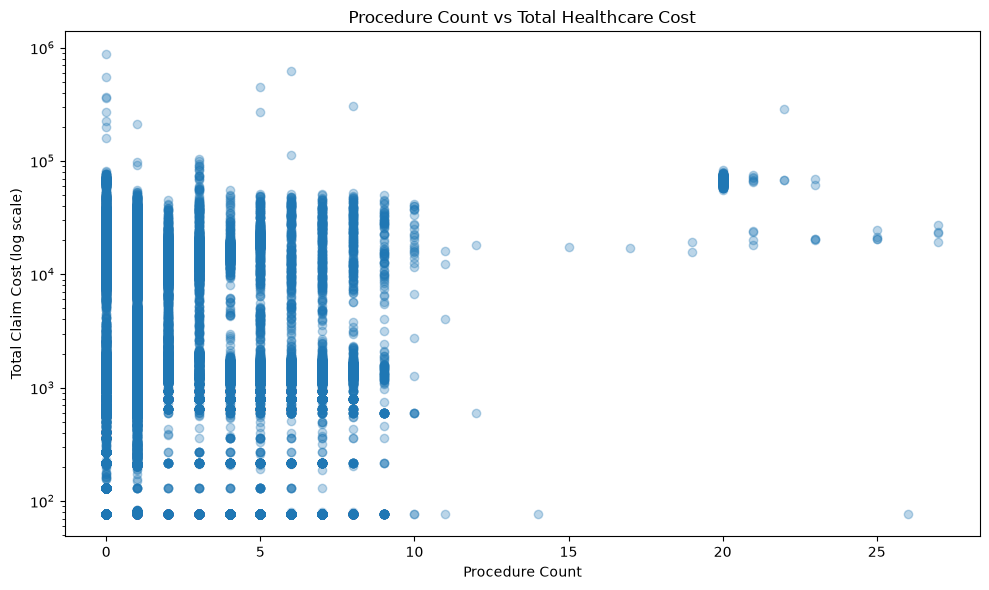

In [26]:
# Q4 — Step 3: Procedure Count vs Healthcare Cost

plt.figure(figsize=(10, 6))

plt.scatter(
    master["procedure_count"],
    master["TOTAL_CLAIM_COST"],
    alpha=0.3
)

plt.yscale("log")

plt.xlabel("Procedure Count")
plt.ylabel("Total Claim Cost (log scale)")
plt.title("Procedure Count vs Total Healthcare Cost")

plt.tight_layout()
plt.show()

In [27]:
# Q4 — Step 3: Average Healthcare Cost by Procedure Utilization

master["PROCEDURE_GROUP"] = pd.cut(
    master["procedure_count"],
    bins=[-1, 0, 1, 3, 5, float("inf")],
    labels=["0", "1", "2–3", "4–5", "6+"]
)

procedure_cost_summary = (
    master
    .groupby("PROCEDURE_GROUP", observed=False)
    .agg(
        Encounter_Count=("Id", "count"),
        Total_Cost=("TOTAL_CLAIM_COST", "sum"),
        Average_Cost=("TOTAL_CLAIM_COST", "mean"),
        Median_Cost=("TOTAL_CLAIM_COST", "median")
    )
)

procedure_cost_summary

,Encounter_Count,Total_Cost,Average_Cost,Median_Cost
PROCEDURE_GROUP,,,,
0,35605,63192951.00,1774.833619,269.68
1,10746,80140226.86,7457.679775,3178.36
2–3,5609,49594197.97,8841.896589,9034.31
4–5,4235,19570551.29,4621.145523,926.85
6+,5264,42535900.96,8080.528298,1248.80


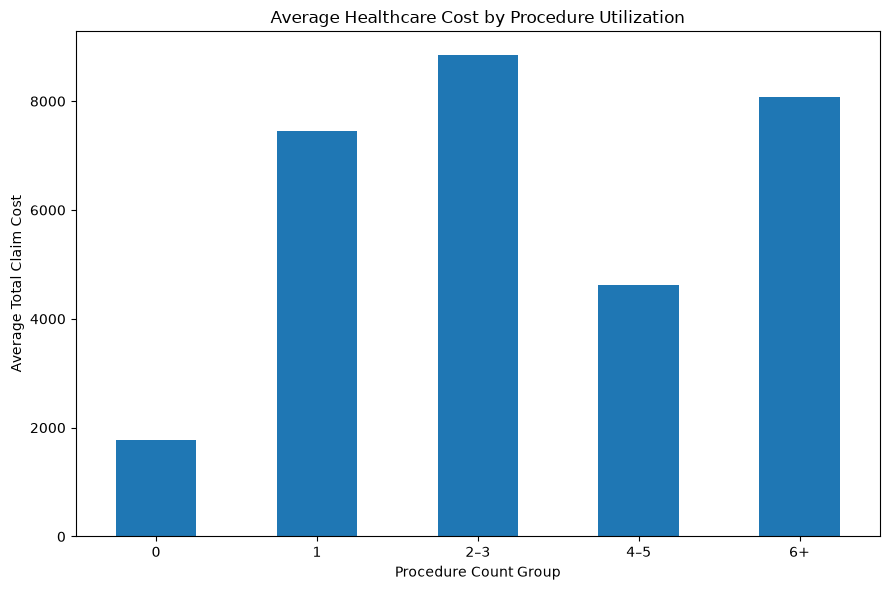

In [28]:
# Q4 — Procedure Utilization vs Cost Visualization

plt.figure(figsize=(9, 6))

procedure_cost_summary["Average_Cost"].plot(kind="bar")

plt.xlabel("Procedure Count Group")
plt.ylabel("Average Total Claim Cost")
plt.title("Average Healthcare Cost by Procedure Utilization")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [29]:
# Q4 — Step 4: Average Healthcare Cost by Medication Utilization

master["MEDICATION_GROUP"] = pd.cut(
    master["medication_count"],
    bins=[-1, 0, 1, 2, 3, float("inf")],
    labels=["0", "1", "2", "3", "4+"]
)

medication_cost_summary = (
    master
    .groupby("MEDICATION_GROUP", observed=False)
    .agg(
        Encounter_Count=("Id", "count"),
        Total_Cost=("TOTAL_CLAIM_COST", "sum"),
        Average_Cost=("TOTAL_CLAIM_COST", "mean"),
        Median_Cost=("TOTAL_CLAIM_COST", "median")
    )
)

medication_cost_summary

,Encounter_Count,Total_Cost,Average_Cost,Median_Cost
MEDICATION_GROUP,,,,
0,34588,1.711909e+08,4949.429011,786.33
1,12122,1.787605e+07,1474.678373,635.40
2,7031,2.117340e+07,3011.434844,786.33
3,4653,1.398610e+07,3005.824451,786.33
4+,3065,3.080743e+07,10051.362695,1129.25


In [30]:
# Q5 — Step 1: Clinical Cost Component Summary

clinical_cost_columns = [
    "procedure_cost",
    "medication_cost",
    "immunization_cost",
    "TOTAL_CLAIM_COST"
]

clinical_cost_summary = (
    master[clinical_cost_columns]
    .describe()
    .T
)

clinical_cost_summary

,count,mean,std,min,25%,50%,75%,max
procedure_cost,61459.0,3420.183538,9254.422543,0.0,0.00,0.00,2621.72,625825.22
medication_cost,61459.0,1202.554751,19537.958963,0.0,0.00,0.00,14.96,2197449.71
immunization_cost,61459.0,38.889417,101.478596,0.0,0.00,0.00,0.00,702.60
TOTAL_CLAIM_COST,61459.0,4149.657952,10919.677889,0.0,129.16,786.33,1625.89,873646.19


In [31]:
# Q5 — Step 2: Non-zero Clinical Cost Analysis

clinical_components = [
    "procedure_cost",
    "medication_cost",
    "immunization_cost"
]

clinical_nonzero_summary = []

for col in clinical_components:
    nonzero_count = (master[col] > 0).sum()
    zero_count = (master[col] == 0).sum()
    total_value = master[col].sum()
    nonzero_mean = master.loc[master[col] > 0, col].mean()
    
    clinical_nonzero_summary.append({
        "Cost Component": col,
        "Zero Cost Encounters": zero_count,
        "Non-Zero Cost Encounters": nonzero_count,
        "Non-Zero %": (nonzero_count / len(master)) * 100,
        "Total Component Cost": total_value,
        "Average Among Non-Zero": nonzero_mean
    })

clinical_nonzero_summary = pd.DataFrame(clinical_nonzero_summary)

clinical_nonzero_summary

,Cost Component,Zero Cost Encounters,Non-Zero Cost Encounters,Non-Zero %,Total Component Cost,Average Among Non-Zero
0,procedure_cost,35605,25854,42.067069,2.102011e+08,8130.310979
1,medication_cost,34588,26871,43.721831,7.390781e+07,2750.467509
2,immunization_cost,49663,11796,19.193283,2.390105e+06,202.619929


In [32]:
# Q5 — Step 3: Top 1% Concentration of Clinical Costs

clinical_components = [
    "procedure_cost",
    "medication_cost",
    "immunization_cost"
]

top1_results = []

for col in clinical_components:
    total = master[col].sum()
    
    top_n = int(len(master) * 0.01)
    
    top1_cost = (
        master[col]
        .sort_values(ascending=False)
        .head(top_n)
        .sum()
    )
    
    top1_results.append({
        "Cost Component": col,
        "Total Component Cost": total,
        "Top 1% Encounter Cost": top1_cost,
        "Top 1% Cost Share (%)": (top1_cost / total * 100) if total > 0 else 0
    })

top1_results = pd.DataFrame(top1_results)

top1_results

,Cost Component,Total Component Cost,Top 1% Encounter Cost,Top 1% Cost Share (%)
0,procedure_cost,2.102011e+08,38350888.31,18.244860
1,medication_cost,7.390781e+07,44328584.08,59.978212
2,immunization_cost,2.390105e+06,427321.32,17.878770


In [33]:
# Q5 — Step 4: Clinical Cost vs Total Claim Cost

clinical_cost_corr = (
    master[
        ["procedure_cost", "medication_cost",
         "immunization_cost", "TOTAL_CLAIM_COST"]
    ]
    .corr()["TOTAL_CLAIM_COST"]
    .drop("TOTAL_CLAIM_COST")
    .sort_values(ascending=False)
)

clinical_cost_corr

procedure_cost       0.736641
medication_cost      0.044741
immunization_cost   -0.088059
Name: TOTAL_CLAIM_COST, dtype: float64

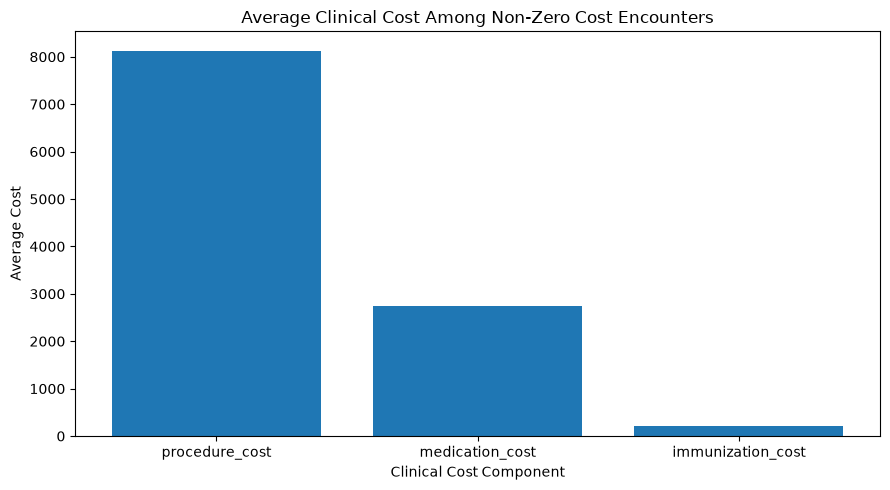

In [34]:
# Q5 — Visualization: Average Cost Among Non-Zero Clinical Cost Encounters

plot_data = clinical_nonzero_summary.copy()

plt.figure(figsize=(9, 5))

plt.bar(
    plot_data["Cost Component"],
    plot_data["Average Among Non-Zero"]
)

plt.title("Average Clinical Cost Among Non-Zero Cost Encounters")
plt.xlabel("Clinical Cost Component")
plt.ylabel("Average Cost")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [36]:
# Q6 — Step 1: Provider and Organization Overview

provider_summary = {
    "Unique Providers": master["PROVIDER"].nunique(),
    "Unique Provider Specialties": master["PROVIDER_SPECIALITY"].nunique(),
    "Unique Organizations": master["PROVIDER_ORGANIZATION"].nunique(),
    "Unique Organization States": master["ORGANIZATION_STATE"].nunique()
}

provider_org_overview = pd.DataFrame(
    provider_summary.items(),
    columns=["Metric", "Value"]
)

provider_org_overview

,Metric,Value
0,Unique Providers,1123
1,Unique Provider Specialties,1
2,Unique Organizations,1122
3,Unique Organization States,1


In [37]:
# Q6 — Step 2: Cost by Provider Specialty

specialty_summary = (
    master.groupby("PROVIDER_SPECIALITY")
    .agg(
        Encounter_Count=("Id", "count"),
        Total_Cost=("TOTAL_CLAIM_COST", "sum"),
        Average_Cost=("TOTAL_CLAIM_COST", "mean"),
        Median_Cost=("TOTAL_CLAIM_COST", "median")
    )
    .sort_values("Total_Cost", ascending=False)
)

specialty_summary

,Encounter_Count,Total_Cost,Average_Cost,Median_Cost
PROVIDER_SPECIALITY,,,,
GENERAL PRACTICE,61459,2.550338e+08,4149.657952,786.33


In [38]:
# Q6 — Step 3: Specialty Analysis with Minimum Encounter Threshold

specialty_filtered = (
    specialty_summary[
        specialty_summary["Encounter_Count"] >= 100
    ]
    .sort_values("Average_Cost", ascending=False)
)

specialty_filtered

,Encounter_Count,Total_Cost,Average_Cost,Median_Cost
PROVIDER_SPECIALITY,,,,
GENERAL PRACTICE,61459,2.550338e+08,4149.657952,786.33


In [39]:
# Q6 — Step 4: Top Specialties by Average Cost

top_specialties_by_avg = (
    specialty_filtered
    .sort_values("Average_Cost", ascending=False)
    .head(10)
)

top_specialties_by_avg

,Encounter_Count,Total_Cost,Average_Cost,Median_Cost
PROVIDER_SPECIALITY,,,,
GENERAL PRACTICE,61459,2.550338e+08,4149.657952,786.33


In [41]:
# Q6 — Step 5: Top Specialties by Total Cost

top_specialties_by_total = (
    specialty_filtered
    .sort_values("Total_Cost", ascending=False)
    .head(10)
)

top_specialties_by_total

,Encounter_Count,Total_Cost,Average_Cost,Median_Cost
PROVIDER_SPECIALITY,,,,
GENERAL PRACTICE,61459,2.550338e+08,4149.657952,786.33


In [42]:
# Q6 — Step 6: Provider-Level Cost Summary

provider_cost_summary = (
    master.groupby(["PROVIDER", "PROVIDER_SPECIALITY"])
    .agg(
        Encounter_Count=("Id", "count"),
        Total_Cost=("TOTAL_CLAIM_COST", "sum"),
        Average_Cost=("TOTAL_CLAIM_COST", "mean"),
        Median_Cost=("TOTAL_CLAIM_COST", "median"),
        Provider_Utilization=("PROVIDER_UTILIZATION", "mean")
    )
    .reset_index()
)

provider_cost_summary.head(10)

,PROVIDER,PROVIDER_SPECIALITY,Encounter_Count,Total_Cost,Average_Cost,Median_Cost,Provider_Utilization
0,0013f086-e105-3a24-8b5b-93472864bba7,GENERAL PRACTICE,7,7198.61,1028.372857,786.330,34.0
1,0082cdc6-7774-3e65-afb5-5df6c85cb839,GENERAL PRACTICE,76,186573.65,2454.916447,1188.215,119.0
2,00b2a63e-a2af-3d37-81d3-8a8c768ad62b,GENERAL PRACTICE,80,229568.87,2869.610875,1087.550,124.0
3,00d4df52-d2d9-3f6f-8ba5-6273d3e0b6a8,GENERAL PRACTICE,5,6060.79,1212.158000,1112.430,32.0
4,00f428d7-bfd6-34fa-b0cb-bb6f63385bb3,GENERAL PRACTICE,15,17601.73,1173.448667,1131.050,63.0
5,0152c3ea-a79e-39ea-9837-1f722de654be,GENERAL PRACTICE,20,20511.29,1025.564500,856.590,47.0
6,0187f4b4-8914-33e9-8017-368a1403b56c,GENERAL PRACTICE,36,38305.71,1064.047500,926.850,69.0
7,018959ff-6c7b-31ad-a2a0-04e54f873414,GENERAL PRACTICE,10,9921.32,992.132000,856.590,27.0
8,019847d9-0ecf-3542-8d08-d657a8dbe665,GENERAL PRACTICE,25,24642.39,985.695600,926.850,52.0
9,01e50ec8-8cf7-3f62-8c72-9bdc0453fcd4,GENERAL PRACTICE,69,221863.92,3215.419130,218.010,328.0


In [43]:
# Q6 — Step 7: Providers with Minimum Encounter Threshold

provider_filtered = (
    provider_cost_summary[
        provider_cost_summary["Encounter_Count"] >= 100
    ]
    .copy()
)

provider_filtered.shape

(86, 7)

In [44]:
# Q6 — Step 8: Top Providers by Average Encounter Cost

top_providers_by_avg = (
    provider_filtered
    .sort_values("Average_Cost", ascending=False)
    .head(10)
)

top_providers_by_avg

,PROVIDER,PROVIDER_SPECIALITY,Encounter_Count,Total_Cost,Average_Cost,Median_Cost,Provider_Utilization
908,ce615fe9-f785-3bbc-ba96-43c329746491,GENERAL PRACTICE,135,3690668.34,27338.284000,26977.860,309.0
531,7a112976-6ab3-3811-86bc-ad86d1928fa5,GENERAL PRACTICE,192,4861869.92,25322.239167,26821.455,522.0
438,62c53dbf-0f4e-3716-9bb5-cba7e411d7a4,GENERAL PRACTICE,579,7773134.39,13425.102573,1657.770,694.0
137,2023a799-2651-317f-942e-af7d42ced2d9,GENERAL PRACTICE,182,2004804.41,11015.408846,10273.645,481.0
484,701f23b0-fe1c-31b9-acf6-3bbe2b173716,GENERAL PRACTICE,716,7415380.54,10356.676732,594.140,1692.0
857,c389231c-52b6-30d4-a8a9-002f09992142,GENERAL PRACTICE,232,2323639.34,10015.686810,8177.465,466.0
900,ccc1c3fd-3418-3658-9325-3cc6c6a085c2,GENERAL PRACTICE,664,6497523.44,9785.426867,1142.035,740.0
780,b496084f-cadd-3edc-bfdf-4ef1ace0af58,GENERAL PRACTICE,551,5234289.20,9499.617423,129.160,1071.0
697,9f529022-166f-3db4-9f92-ff1ba11ee565,GENERAL PRACTICE,365,3348478.25,9173.913014,8939.180,747.0
794,b7ccd823-5152-3c05-903b-7058f518495e,GENERAL PRACTICE,244,2104156.57,8623.592500,8526.440,576.0


In [45]:
# Q6 — Step 9: Top Providers by Total Cost

top_providers_by_total = (
    provider_filtered
    .sort_values("Total_Cost", ascending=False)
    .head(10)
)

top_providers_by_total

,PROVIDER,PROVIDER_SPECIALITY,Encounter_Count,Total_Cost,Average_Cost,Median_Cost,Provider_Utilization
438,62c53dbf-0f4e-3716-9bb5-cba7e411d7a4,GENERAL PRACTICE,579,7773134.39,13425.102573,1657.770,694.0
757,b0c5743a-4f9a-33b3-bab4-6a474fcf9ffd,GENERAL PRACTICE,1477,7717062.34,5224.822167,129.160,3954.0
484,701f23b0-fe1c-31b9-acf6-3bbe2b173716,GENERAL PRACTICE,716,7415380.54,10356.676732,594.140,1692.0
397,581cc2bd-9005-3008-8abb-299f40d36ca5,GENERAL PRACTICE,1010,7111881.18,7041.466515,645.810,2706.0
293,43b6d00b-7643-36f8-8043-456d4eda39eb,GENERAL PRACTICE,2184,6599341.65,3021.676580,884.540,3409.0
900,ccc1c3fd-3418-3658-9325-3cc6c6a085c2,GENERAL PRACTICE,664,6497523.44,9785.426867,1142.035,740.0
809,bb49afa2-3d8a-306c-a06e-a1715dd71af8,GENERAL PRACTICE,835,6495903.15,7779.524731,2044.350,2226.0
1096,faa87618-81eb-3ac8-923b-bf203be11e67,GENERAL PRACTICE,1105,6299498.08,5700.903240,358.530,2238.0
250,3aade15e-5333-3c4e-86c5-aab3511bc8e8,GENERAL PRACTICE,1020,6168896.27,6047.937520,594.140,2877.0
738,aa2c2d64-bf7c-3eba-af47-ea9b5794c86e,GENERAL PRACTICE,765,6033325.07,7886.699438,645.810,2555.0


In [46]:
# Q6 — Step 10: Provider Utilization vs Average Cost

provider_utilization_corr = (
    provider_filtered[
        ["Provider_Utilization", "Average_Cost"]
    ]
    .corr()
)

provider_utilization_corr

,Provider_Utilization,Average_Cost
Provider_Utilization,1.000000,0.086343
Average_Cost,0.086343,1.000000


In [47]:
# Q6 — Step 11: Provider Utilization Summary

provider_utilization_summary = (
    provider_filtered[
        ["Provider_Utilization", "Average_Cost", "Encounter_Count"]
    ]
    .describe()
)

provider_utilization_summary

,Provider_Utilization,Average_Cost,Encounter_Count
count,86.000000,86.000000,86.000000
mean,1093.813953,5365.960734,451.255814
std,938.697477,4340.268017,365.294923
min,117.000000,143.742264,103.000000
25%,366.000000,2798.238432,172.250000
50%,729.000000,5137.380481,347.500000
75%,1712.250000,6857.101380,673.000000
max,3954.000000,27338.284000,2184.000000


In [48]:
# Q6 — Step 12: Organization-Level Cost Summary

organization_summary = (
    master.groupby(
        ["PROVIDER_ORGANIZATION", "ORGANIZATION_NAME", "ORGANIZATION_CITY", "ORGANIZATION_STATE"]
    )
    .agg(
        Encounter_Count=("Id", "count"),
        Total_Cost=("TOTAL_CLAIM_COST", "sum"),
        Average_Cost=("TOTAL_CLAIM_COST", "mean"),
        Median_Cost=("TOTAL_CLAIM_COST", "median"),
        Organization_Utilization=("ORGANIZATION_UTILIZATION", "mean")
    )
    .reset_index()
)

organization_summary.head(10)

,PROVIDER_ORGANIZATION,ORGANIZATION_NAME,ORGANIZATION_CITY,ORGANIZATION_STATE,Encounter_Count,Total_Cost,Average_Cost,Median_Cost,Organization_Utilization
0,00205a66-c6f3-31b1-8759-5d1ecabd830c,RENAL AND TRANSPLANT ASSOCIATES OF NEW ENGLAND PC,WORCESTER,MA,28,28245.27,1008.759643,856.590,66.0
1,00312a4d-df26-32b6-9924-683879cffdc8,PCP28711,BELMONT,MA,59,57196.37,969.430000,786.330,70.0
2,00b14d27-ca1c-33b6-ab79-b636bf184d1a,PCP44286,MENDON,MA,39,35807.58,918.143077,786.330,80.0
3,0154718e-fb2d-3969-bbf8-045641fe7dc9,PCP32178,EASTHAMPTON,MA,23,26493.98,1151.912174,1143.110,49.0
4,015a3415-7c25-3d6e-afc5-1fe1000cbd0b,CAMBRIDGE PUBLIC HEALTH COMMISSION,SOMERVILLE,MA,5,4072.17,814.434000,786.330,28.0
5,027988f5-9d2d-367f-a9a4-7daafe78bf61,PCP25103,NEWTON,MA,67,64646.15,964.867910,786.330,77.0
6,02cf7c70-4cf8-3a69-8e55-f1e4201179a3,PCP189485,SEEKONK,MA,7,7944.68,1134.954286,1209.240,30.0
7,02e72226-b75f-3e06-990a-007394b72f87,NORTH SHORE PHYSICIANS GROUP INC,BEVERLY,MA,6,7932.99,1322.165000,1351.455,31.0
8,03347b4d-994e-302b-848b-58019a4e274d,EMERSON HOSPITAL -,W CONCORD,MA,422,2078491.72,4925.335829,129.160,931.0
9,036e3ac3-cf03-3aef-982e-cce75baed820,PCP10937,CHARLTON,MA,12,7160.13,596.677500,773.385,12.0


In [50]:
# Q6 — Step 13: Organizations with Minimum Encounter Threshold

organization_filtered = (
    organization_summary[
        organization_summary["Encounter_Count"] >= 100
    ]
    .copy()
)

organization_filtered.shape

(86, 9)

In [51]:
# Q6 — Step 14: Top Organizations by Average Encounter Cost

top_organizations_by_avg = (
    organization_filtered
    .sort_values("Average_Cost", ascending=False)
    .head(10)
)

top_organizations_by_avg

,PROVIDER_ORGANIZATION,ORGANIZATION_NAME,ORGANIZATION_CITY,ORGANIZATION_STATE,Encounter_Count,Total_Cost,Average_Cost,Median_Cost,Organization_Utilization
1119,ff9474cb-cf9c-350a-a22b-b949ee9793cf,FAMILY CARE MEDICAL CENTER / URGENT CARE PHYSI...,SPRINGFIELD,MA,135,3690668.34,27338.284000,26977.860,309.0
803,b81688f5-bd0e-3c99-963f-860d3e90ab5d,URGENT CARE MEDICAL CLINIC,BOSTON,MA,192,4861869.92,25322.239167,26821.455,522.0
826,be4c63f3-8d38-3fa9-a183-62045b5c85f6,VA Boston Healthcare System Jamaica Plain Campus,Jamaica Plain,MA,579,7773134.39,13425.102573,1657.770,694.0
301,44bef9d3-91c2-3005-93e0-ccf436348ff0,MASSACHUSETTS EYE AND EAR INFIRMARY -,BOSTON,MA,182,2004804.41,11015.408846,10273.645,481.0
1032,ecc51621-0af3-3b35-ac3e-8b1e34022e92,SAINT ANNE'S HOSPITAL,FALL RIVER,MA,716,7415380.54,10356.676732,594.140,1692.0
1112,fd328395-ab1d-35c6-a2d0-d05a9a79cf11,MERCY MEDICAL CTR,SPRINGFIELD,MA,232,2323639.34,10015.686810,8177.465,466.0
242,37eb7694-de8f-3407-b95f-1a6a31fb0f6a,Springfield Outpatient Clinic,Springfield,MA,664,6497523.44,9785.426867,1142.035,740.0
1086,f7a6cc79-3075-3124-9f62-6fe562440b1d,HAWTHORN MEDICAL URGENT CARE CENTER,NORTH DARTMOUTH,MA,551,5234289.20,9499.617423,129.160,1071.0
363,5103c940-0c08-392f-95cd-446e0cea042a,SHRINERS' HOSPITAL FOR CHILDREN (THE),SPRINGFIELD,MA,365,3348478.25,9173.913014,8939.180,747.0
621,8b58cdd1-3d79-3126-8fe0-da2c54d6805c,CARNEY HOSPITAL,BOSTON,MA,244,2104156.57,8623.592500,8526.440,576.0


In [52]:
# Q6 — Step 15: Top Organizations by Total Cost

top_organizations_by_total = (
    organization_filtered
    .sort_values("Total_Cost", ascending=False)
    .head(10)
)

top_organizations_by_total

,PROVIDER_ORGANIZATION,ORGANIZATION_NAME,ORGANIZATION_CITY,ORGANIZATION_STATE,Encounter_Count,Total_Cost,Average_Cost,Median_Cost,Organization_Utilization
826,be4c63f3-8d38-3fa9-a183-62045b5c85f6,VA Boston Healthcare System Jamaica Plain Campus,Jamaica Plain,MA,579,7773134.39,13425.102573,1657.770,694.0
316,4861d01f-019c-3dac-a153-8334e50919f9,NORTH SHORE MEDICAL CENTER -,SALEM,MA,1477,7717062.34,5224.822167,129.160,3954.0
1032,ecc51621-0af3-3b35-ac3e-8b1e34022e92,SAINT ANNE'S HOSPITAL,FALL RIVER,MA,716,7415380.54,10356.676732,594.140,1692.0
972,e002090d-4e92-300e-b41e-7d1f21dee4c6,CAMBRIDGE HEALTH ALLIANCE,CAMBRIDGE,MA,1010,7111881.18,7041.466515,645.810,2706.0
510,6f122869-a856-3d65-8db9-099bf4f5bbb8,LAHEY HOSPITAL & MEDICAL CENTER BURLINGTON,BURLINGTON,MA,2184,6599341.65,3021.676580,884.540,3409.0
242,37eb7694-de8f-3407-b95f-1a6a31fb0f6a,Springfield Outpatient Clinic,Springfield,MA,664,6497523.44,9785.426867,1142.035,740.0
143,226098a2-6a40-3588-b5bb-db56c3a30a04,GOOD SAMARITAN MEDICAL CENTER,BROCKTON,MA,835,6495903.15,7779.524731,2044.350,2226.0
924,d692e283-0833-3201-8e55-4f868a9c0736,HALLMARK HEALTH SYSTEM,MELROSE,MA,1105,6299498.08,5700.903240,358.530,2238.0
481,69176529-fd1f-3b3f-abce-a0a3626769eb,MOUNT AUBURN HOSPITAL,CAMBRIDGE,MA,1020,6168896.27,6047.937520,594.140,2877.0
1073,f4e7709c-02f6-37ca-aeea-8247d74e88e7,WINCHESTER HOSPITAL,WINCHESTER,MA,765,6033325.07,7886.699438,645.810,2555.0


In [53]:
# Q6 — Step 16: Organization Utilization vs Average Cost

organization_utilization_corr = (
    organization_filtered[
        ["Organization_Utilization", "Average_Cost"]
    ]
    .corr()
)

organization_utilization_corr

,Organization_Utilization,Average_Cost
Organization_Utilization,1.000000,0.086343
Average_Cost,0.086343,1.000000


In [54]:
# Q6 — Step 17: Cost by Organization State

state_cost_summary = (
    master.groupby("ORGANIZATION_STATE")
    .agg(
        Encounter_Count=("Id", "count"),
        Total_Cost=("TOTAL_CLAIM_COST", "sum"),
        Average_Cost=("TOTAL_CLAIM_COST", "mean"),
        Median_Cost=("TOTAL_CLAIM_COST", "median")
    )
    .sort_values("Total_Cost", ascending=False)
)

state_cost_summary

,Encounter_Count,Total_Cost,Average_Cost,Median_Cost
ORGANIZATION_STATE,,,,
MA,61459,2.550338e+08,4149.657952,786.33


In [55]:
# Q6 — Step 17: Cost by Organization State

state_cost_summary = (
    master.groupby("ORGANIZATION_STATE")
    .agg(
        Encounter_Count=("Id", "count"),
        Total_Cost=("TOTAL_CLAIM_COST", "sum"),
        Average_Cost=("TOTAL_CLAIM_COST", "mean"),
        Median_Cost=("TOTAL_CLAIM_COST", "median")
    )
    .sort_values("Total_Cost", ascending=False)
)

state_cost_summary

,Encounter_Count,Total_Cost,Average_Cost,Median_Cost
ORGANIZATION_STATE,,,,
MA,61459,2.550338e+08,4149.657952,786.33


In [56]:
# Q6 — Step 18: State Analysis with Minimum Encounter Threshold

state_filtered = (
    state_cost_summary[
        state_cost_summary["Encounter_Count"] >= 100
    ]
    .sort_values("Average_Cost", ascending=False)
)

state_filtered

,Encounter_Count,Total_Cost,Average_Cost,Median_Cost
ORGANIZATION_STATE,,,,
MA,61459,2.550338e+08,4149.657952,786.33


In [57]:
# Q6 — Step 19: Top States by Average Encounter Cost

top_states_by_avg = (
    state_filtered
    .head(10)
)

top_states_by_avg

,Encounter_Count,Total_Cost,Average_Cost,Median_Cost
ORGANIZATION_STATE,,,,
MA,61459,2.550338e+08,4149.657952,786.33


In [60]:
# Q6 — Step 20: Top States by Total Cost

top_states_by_total = (
    state_cost_summary
    .head(10)
)

top_states_by_total

,Encounter_Count,Total_Cost,Average_Cost,Median_Cost
ORGANIZATION_STATE,,,,
MA,61459,2.550338e+08,4149.657952,786.33


In [62]:
# Q6 — Step 21: Consolidated Utilization-Cost Correlation

q6_correlations = pd.DataFrame({
    "Level": [
        "Provider",
        "Organization"
    ],
    "Utilization_Cost_Correlation": [
        provider_filtered["Provider_Utilization"].corr(
            provider_filtered["Average_Cost"]
        ),
        organization_filtered["Organization_Utilization"].corr(
            organization_filtered["Average_Cost"]
        )
    ]
})

q6_correlations

,Level,Utilization_Cost_Correlation
0,Provider,0.086343
1,Organization,0.086343


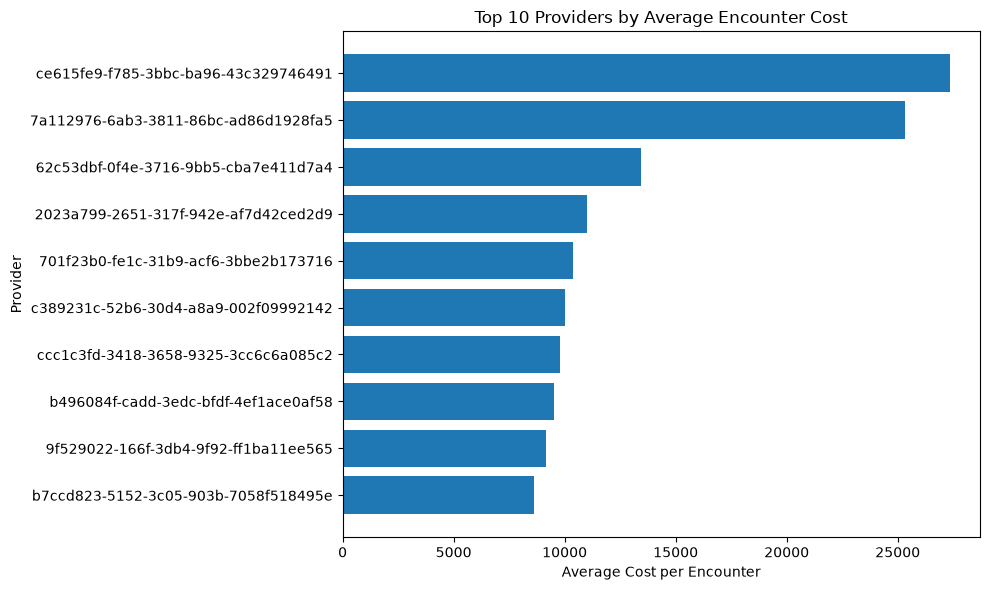

In [66]:
# Q6 - Visualization 1
# Top 10 Providers by Average Cost
# Only providers with at least 100 encounters

top_provider_avg = (
    provider_filtered
    .sort_values("Average_Cost", ascending=False)
    .head(10)
    .sort_values("Average_Cost", ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_provider_avg["PROVIDER"],
    top_provider_avg["Average_Cost"]
)

plt.xlabel("Average Cost per Encounter")
plt.ylabel("Provider")
plt.title("Top 10 Providers by Average Encounter Cost")

plt.tight_layout()
plt.show()

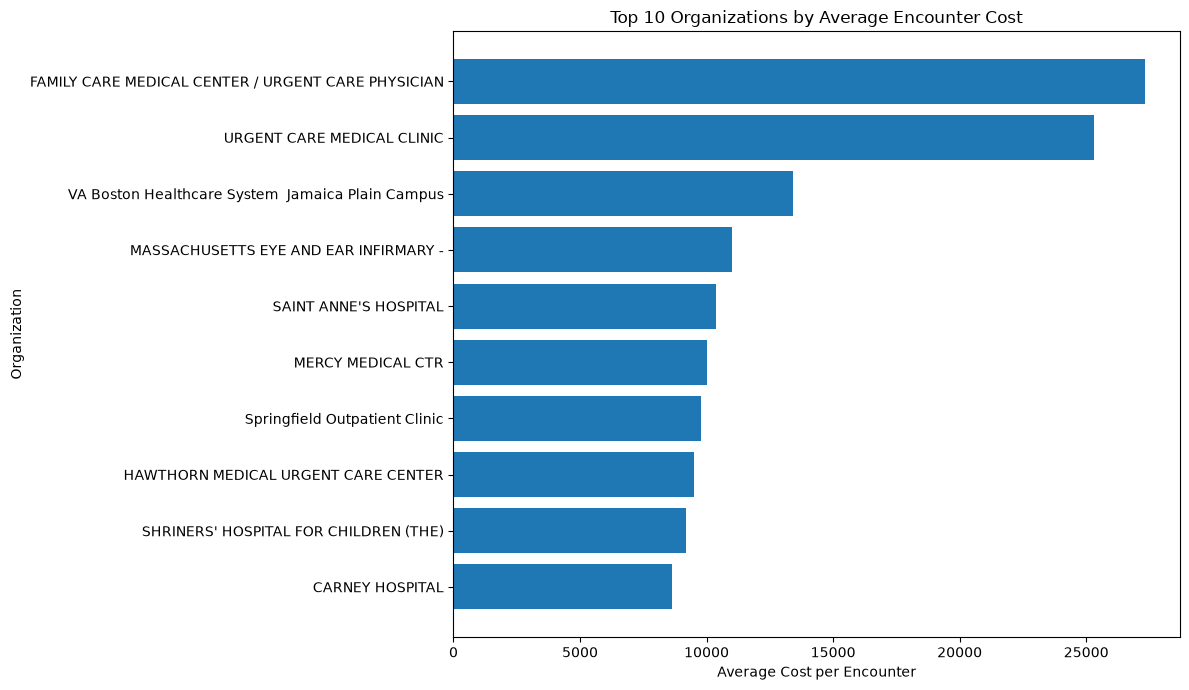

In [67]:
# Q6 - Visualization 2
# Top 10 Organizations by Average Cost
# Only organizations with at least 100 encounters

top_org_avg = (
    organization_filtered
    .sort_values("Average_Cost", ascending=False)
    .head(10)
    .sort_values("Average_Cost", ascending=True)
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_org_avg["ORGANIZATION_NAME"],
    top_org_avg["Average_Cost"]
)

plt.xlabel("Average Cost per Encounter")
plt.ylabel("Organization")
plt.title("Top 10 Organizations by Average Encounter Cost")

plt.tight_layout()
plt.show()

In [68]:
# Q7 - Step 1
# Payer-level cost overview

payer_summary = (
    master.groupby("PAYER_NAME")
    .agg(
        Encounter_Count=("Id", "count"),
        Total_Cost=("TOTAL_CLAIM_COST", "sum"),
        Average_Cost=("TOTAL_CLAIM_COST", "mean"),
        Median_Cost=("TOTAL_CLAIM_COST", "median"),
        Total_Coverage=("PAYER_AMOUNT_COVERED", "sum")
    )
    .sort_values("Total_Cost", ascending=False)
)

payer_summary

,Encounter_Count,Total_Cost,Average_Cost,Median_Cost,Total_Coverage
PAYER_NAME,,,,,
NO_INSURANCE,13620,1.015495e+08,7455.913347,1304.83,0.000000e+00
Medicare,8482,3.233993e+07,3812.771399,129.16,3.070195e+11
Medicaid,5283,2.596603e+07,4915.015557,831.76,6.335007e+11
Blue Cross Blue Shield,5950,1.781868e+07,2994.735706,786.33,2.062628e+11
Anthem,5532,1.634463e+07,2954.560575,786.33,6.927196e+09
Aetna,5767,1.601648e+07,2777.263102,786.33,9.391719e+09
Cigna Health,5100,1.469978e+07,2882.309949,786.33,6.622519e+09
Humana,5635,1.441823e+07,2558.691892,786.33,5.888877e+09
UnitedHealthcare,5247,1.385124e+07,2639.839857,786.33,5.140809e+09


In [69]:
# Q7 - Step 2
# Percentage of total healthcare cost by payer

payer_summary["Cost_Share_%"] = (
    payer_summary["Total_Cost"]
    / payer_summary["Total_Cost"].sum()
    * 100
)

payer_summary.sort_values(
    "Cost_Share_%",
    ascending=False
)

,Encounter_Count,Total_Cost,Average_Cost,Median_Cost,Total_Coverage,Cost_Share_%
PAYER_NAME,,,,,,
NO_INSURANCE,13620,1.015495e+08,7455.913347,1304.83,0.000000e+00,39.818067
Medicare,8482,3.233993e+07,3812.771399,129.16,3.070195e+11,12.680642
Medicaid,5283,2.596603e+07,4915.015557,831.76,6.335007e+11,10.181405
Blue Cross Blue Shield,5950,1.781868e+07,2994.735706,786.33,2.062628e+11,6.986790
Anthem,5532,1.634463e+07,2954.560575,786.33,6.927196e+09,6.408808
Aetna,5767,1.601648e+07,2777.263102,786.33,9.391719e+09,6.280138
Cigna Health,5100,1.469978e+07,2882.309949,786.33,6.622519e+09,5.763855
Humana,5635,1.441823e+07,2558.691892,786.33,5.888877e+09,5.653457
UnitedHealthcare,5247,1.385124e+07,2639.839857,786.33,5.140809e+09,5.431138


In [71]:
# Q7 - Step 3
# Payer coverage relative to encounter cost

payer_coverage_summary = (
    master.groupby("PAYER_NAME")
    .agg(
        Encounter_Count=("Id", "count"),
        Average_Claim_Cost=("TOTAL_CLAIM_COST", "mean"),
        Average_Payer_Coverage=("PAYER_COVERAGE", "mean")
    )
    .sort_values("Average_Claim_Cost", ascending=False)
)

payer_coverage_summary

,Encounter_Count,Average_Claim_Cost,Average_Payer_Coverage
PAYER_NAME,,,
NO_INSURANCE,13620,7455.913347,0.000000
Medicaid,5283,4915.015557,4622.968156
Medicare,8482,3812.771399,3023.256833
Blue Cross Blue Shield,5950,2994.735706,1944.699304
Anthem,5532,2954.560575,0.434333
Cigna Health,5100,2882.309949,1.111047
Aetna,5767,2777.263102,1.468145
UnitedHealthcare,5247,2639.839857,0.884972
Humana,5635,2558.691892,0.418020


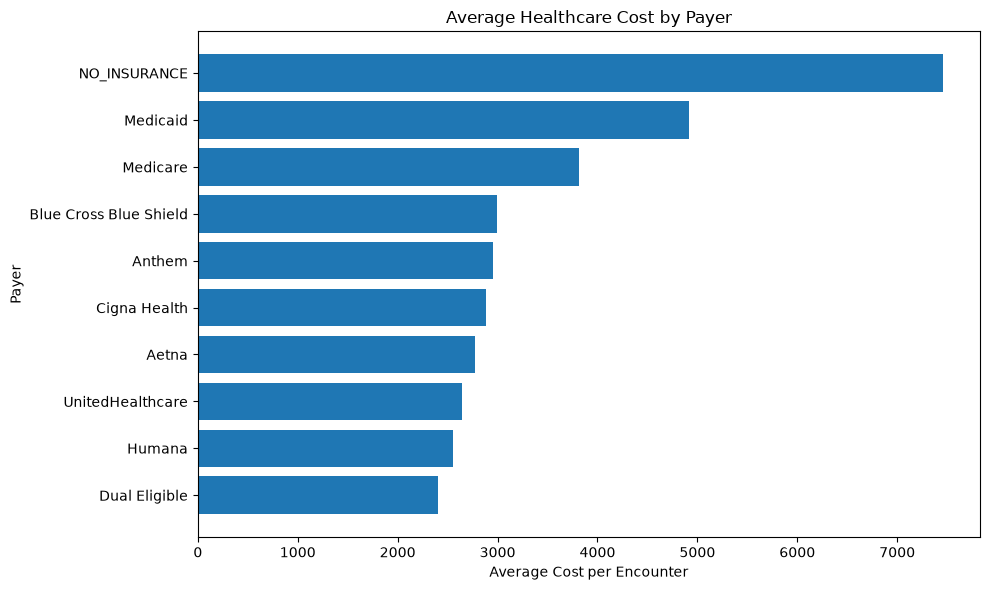

In [72]:
# Q7 - Visualization 1
# Average Healthcare Cost by Payer

plot_data = (
    payer_summary
    .sort_values("Average_Cost", ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data.index,
    plot_data["Average_Cost"]
)

plt.xlabel("Average Cost per Encounter")
plt.ylabel("Payer")
plt.title("Average Healthcare Cost by Payer")

plt.tight_layout()
plt.show()

In [73]:
# Q8 - Step 1
# Identify top 1% high-cost encounters

cost_cutoff = master["TOTAL_CLAIM_COST"].quantile(0.99)

master["HIGH_COST_FLAG"] = (
    master["TOTAL_CLAIM_COST"] >= cost_cutoff
)

high_cost_summary = (
    master["HIGH_COST_FLAG"]
    .value_counts()
    .rename(index={
        False: "Other 99%",
        True: "Top 1%"
    })
)

print("99th percentile cost cutoff:", cost_cutoff)
print()
print(high_cost_summary)

99th percentile cost cutoff: 45209.37999999984

HIGH_COST_FLAG
Other 99%    60844
Top 1%         615
Name: count, dtype: int64


In [74]:
# Q8 - Step 2
# Compare total cost of high-cost encounters with all other encounters

high_cost_cost_summary = (
    master.groupby("HIGH_COST_FLAG")["TOTAL_CLAIM_COST"]
    .agg(["count", "sum", "mean", "median"])
    .rename(index={
        False: "Other 99%",
        True: "Top 1%"
    })
)

high_cost_cost_summary["Cost_Share_%"] = (
    high_cost_cost_summary["sum"]
    / master["TOTAL_CLAIM_COST"].sum()
    * 100
)

high_cost_cost_summary

,count,sum,mean,median,Cost_Share_%
HIGH_COST_FLAG,,,,,
Other 99%,60844,2.115127e+08,3476.310924,786.33,82.93514
Top 1%,615,4.352117e+07,70766.123902,65833.14,17.06486


In [75]:
# Q8 - Step 3
# Compare high-cost encounters across encounter types

high_cost_by_type = (
    master.groupby(["ENCOUNTERCLASS", "HIGH_COST_FLAG"])
    .agg(
        Encounter_Count=("Id", "count"),
        Total_Cost=("TOTAL_CLAIM_COST", "sum"),
        Average_Cost=("TOTAL_CLAIM_COST", "mean")
    )
    .reset_index()
)

high_cost_by_type

,ENCOUNTERCLASS,HIGH_COST_FLAG,Encounter_Count,Total_Cost,Average_Cost
0,ambulatory,False,19670,1.008282e+08,5125.986513
1,ambulatory,True,454,3.046470e+07,67102.874229
2,emergency,False,2122,1.042836e+07,4914.400405
3,emergency,True,46,6.756097e+06,146871.666739
4,inpatient,False,1719,1.403979e+07,8167.419959
5,inpatient,True,9,1.107852e+06,123094.676667
6,outpatient,False,10794,2.859003e+07,2648.696217
7,outpatient,True,43,2.051705e+06,47714.068140
8,urgentcare,False,2538,1.361255e+07,5363.493073
9,urgentcare,True,26,1.254231e+06,48239.660000


In [76]:
# Q8 - Step 4
# Percentage of encounters that are high-cost within each encounter type

high_cost_rate = (
    master.groupby("ENCOUNTERCLASS")
    .agg(
        Total_Encounters=("Id", "count"),
        High_Cost_Encounters=("HIGH_COST_FLAG", "sum")
    )
)

high_cost_rate["High_Cost_Rate_%"] = (
    high_cost_rate["High_Cost_Encounters"]
    / high_cost_rate["Total_Encounters"]
    * 100
)

high_cost_rate.sort_values(
    "High_Cost_Rate_%",
    ascending=False
)

,Total_Encounters,High_Cost_Encounters,High_Cost_Rate_%
ENCOUNTERCLASS,,,
ambulatory,20124,454,2.256013
emergency,2168,46,2.121771
urgentcare,2564,26,1.014041
inpatient,1728,9,0.520833
outpatient,10837,43,0.396789
wellness,24038,37,0.153923


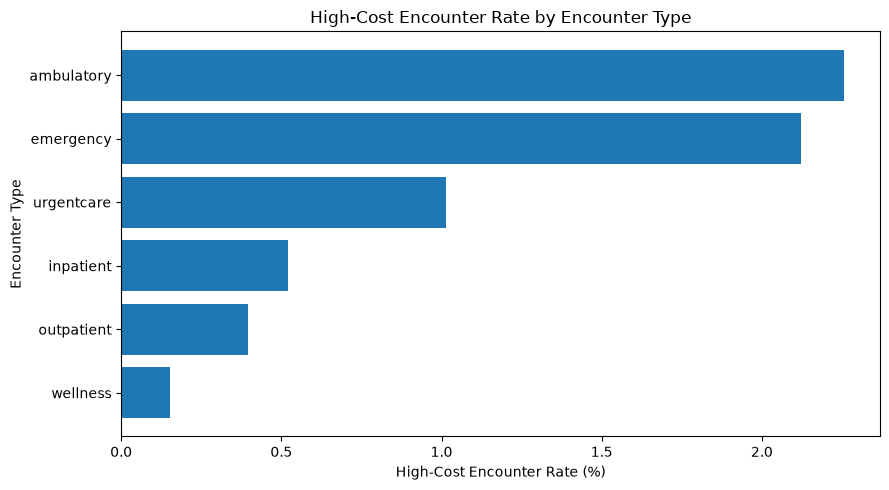

In [77]:
# Q8 - Visualization
# High-cost encounter rate by encounter type

plot_data = high_cost_rate.sort_values(
    "High_Cost_Rate_%",
    ascending=True
)

plt.figure(figsize=(9, 5))

plt.barh(
    plot_data.index,
    plot_data["High_Cost_Rate_%"]
)

plt.xlabel("High-Cost Encounter Rate (%)")
plt.ylabel("Encounter Type")
plt.title("High-Cost Encounter Rate by Encounter Type")

plt.tight_layout()
plt.show()

In [80]:
# Q9 - Step 1
# Identify 30-day repeat encounters

q9_data = master.sort_values(
    ["PATIENT", "START"]
).copy()

# Convert START to datetime for this analysis
q9_data["START"] = pd.to_datetime(
    q9_data["START"],
    errors="coerce"
)

# Get the next encounter date for each patient
q9_data["NEXT_ENCOUNTER_DATE"] = (
    q9_data.groupby("PATIENT")["START"]
    .shift(-1)
)

# Calculate days until the patient's next encounter
q9_data["DAYS_TO_NEXT_ENCOUNTER"] = (
    q9_data["NEXT_ENCOUNTER_DATE"] - q9_data["START"]
).dt.total_seconds() / (24 * 60 * 60)

# Identify encounters followed by another encounter within 30 days
q9_data["REPEAT_30_DAY_FLAG"] = (
    q9_data["DAYS_TO_NEXT_ENCOUNTER"].between(
        0, 30, inclusive="right"
    )
)

print("Total encounters:", len(q9_data))
print()

print(
    q9_data["REPEAT_30_DAY_FLAG"]
    .value_counts()
    .rename(index={
        False: "No repeat within 30 days",
        True: "Repeat within 30 days"
    })
)

Total encounters: 61459

REPEAT_30_DAY_FLAG
No repeat within 30 days    38720
Repeat within 30 days       22739
Name: count, dtype: int64


In [81]:
# Q9 - Step 2
# Compare cost between encounters with and without a 30-day repeat

repeat_cost_summary = (
    q9_data.groupby("REPEAT_30_DAY_FLAG")
    .agg(
        Encounter_Count=("Id", "count"),
        Total_Cost=("TOTAL_CLAIM_COST", "sum"),
        Average_Cost=("TOTAL_CLAIM_COST", "mean"),
        Median_Cost=("TOTAL_CLAIM_COST", "median")
    )
    .rename(index={
        False: "No repeat within 30 days",
        True: "Repeat within 30 days"
    })
)

repeat_cost_summary

,Encounter_Count,Total_Cost,Average_Cost,Median_Cost
REPEAT_30_DAY_FLAG,,,,
No repeat within 30 days,38720,1.113554e+08,2875.914486,786.33
Repeat within 30 days,22739,1.436784e+08,6318.590052,645.81


In [82]:
# Q9 - Step 3
# 30-day repeat rate by encounter type

repeat_by_type = (
    q9_data.groupby("ENCOUNTERCLASS")
    .agg(
        Total_Encounters=("Id", "count"),
        Repeat_30_Day_Encounters=("REPEAT_30_DAY_FLAG", "sum")
    )
)

repeat_by_type["Repeat_Rate_%"] = (
    repeat_by_type["Repeat_30_Day_Encounters"]
    / repeat_by_type["Total_Encounters"]
    * 100
)

repeat_by_type.sort_values(
    "Repeat_Rate_%",
    ascending=False
)

,Total_Encounters,Repeat_30_Day_Encounters,Repeat_Rate_%
ENCOUNTERCLASS,,,
urgentcare,2564,2214,86.349454
ambulatory,20124,11945,59.356987
inpatient,1728,825,47.743056
outpatient,10837,4628,42.705546
emergency,2168,863,39.806273
wellness,24038,2264,9.418421


In [83]:
# Q9 - Step 4
# Cost contribution of 30-day repeat encounters by encounter type

repeat_cost_by_type = (
    q9_data[q9_data["REPEAT_30_DAY_FLAG"]]
    .groupby("ENCOUNTERCLASS")
    .agg(
        Repeat_Encounter_Count=("Id", "count"),
        Total_Repeat_Cost=("TOTAL_CLAIM_COST", "sum"),
        Average_Repeat_Cost=("TOTAL_CLAIM_COST", "mean")
    )
    .sort_values(
        "Total_Repeat_Cost",
        ascending=False
    )
)

repeat_cost_by_type

,Repeat_Encounter_Count,Total_Repeat_Cost,Average_Repeat_Cost
ENCOUNTERCLASS,,,
ambulatory,11945,98888323.61,8278.637389
urgentcare,2214,14044682.81,6343.578505
outpatient,4628,13545294.40,2926.813829
inpatient,825,6120117.68,7418.324461
wellness,2264,5845802.27,2582.068140
emergency,863,5234198.42,6065.119838


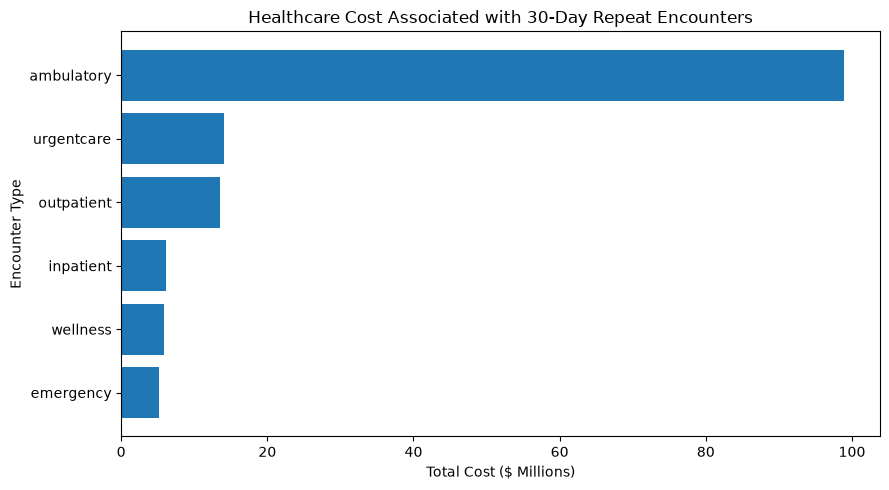

In [84]:
# Q9 - Visualization
# Total cost associated with 30-day repeat encounters

plot_data = repeat_cost_by_type.sort_values(
    "Total_Repeat_Cost",
    ascending=True
)

plt.figure(figsize=(9, 5))

plt.barh(
    plot_data.index,
    plot_data["Total_Repeat_Cost"] / 1_000_000
)

plt.xlabel("Total Cost ($ Millions)")
plt.ylabel("Encounter Type")
plt.title("Healthcare Cost Associated with 30-Day Repeat Encounters")

plt.tight_layout()
plt.show()

In [85]:
# Q10 - Step 1
# Calculate inpatient length of stay

inpatient = master[
    master["ENCOUNTERCLASS"] == "inpatient"
].copy()

# Convert dates to datetime
inpatient["START"] = pd.to_datetime(
    inpatient["START"],
    errors="coerce"
)

inpatient["STOP"] = pd.to_datetime(
    inpatient["STOP"],
    errors="coerce"
)

# Calculate length of stay in days
inpatient["LOS_DAYS"] = (
    inpatient["STOP"] - inpatient["START"]
).dt.total_seconds() / (24 * 60 * 60)

print("Total inpatient encounters:", len(inpatient))
print()

print(
    inpatient["LOS_DAYS"].describe()
)

Total inpatient encounters: 1728

count    1728.000000
mean        4.468159
std       119.914743
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max      4969.000000
Name: LOS_DAYS, dtype: float64


In [86]:
# Q10 - Step 2
# Examine unusually long inpatient stays

los_ranges = pd.Series({
    "1 day": (inpatient["LOS_DAYS"] == 1).sum(),
    "2-7 days": inpatient["LOS_DAYS"].between(2, 7).sum(),
    "8-30 days": inpatient["LOS_DAYS"].between(8, 30).sum(),
    "31-365 days": inpatient["LOS_DAYS"].between(31, 365).sum(),
    "More than 365 days": (inpatient["LOS_DAYS"] > 365).sum()
})

los_ranges

1 day                 1563
2-7 days                63
8-30 days               22
31-365 days              3
More than 365 days       1
dtype: int64

In [87]:
# Q10 - Step 3
# Compare inpatient cost across length-of-stay groups

inpatient["LOS_GROUP"] = pd.cut(
    inpatient["LOS_DAYS"],
    bins=[0, 1, 7, 30, float("inf")],
    labels=["1 day", "2-7 days", "8-30 days", "31+ days"],
    include_lowest=True
)

los_cost_summary = (
    inpatient.groupby("LOS_GROUP", observed=False)
    .agg(
        Encounter_Count=("Id", "count"),
        Total_Cost=("TOTAL_CLAIM_COST", "sum"),
        Average_Cost=("TOTAL_CLAIM_COST", "mean"),
        Median_Cost=("TOTAL_CLAIM_COST", "median")
    )
)

los_cost_summary

,Encounter_Count,Total_Cost,Average_Cost,Median_Cost
LOS_GROUP,,,,
1 day,1563,13112531.06,8389.335291,4139.77
2-7 days,137,1246116.78,9095.742920,5642.21
8-30 days,23,724304.31,31491.491739,20439.82
31+ days,5,64694.85,12938.970000,8120.84


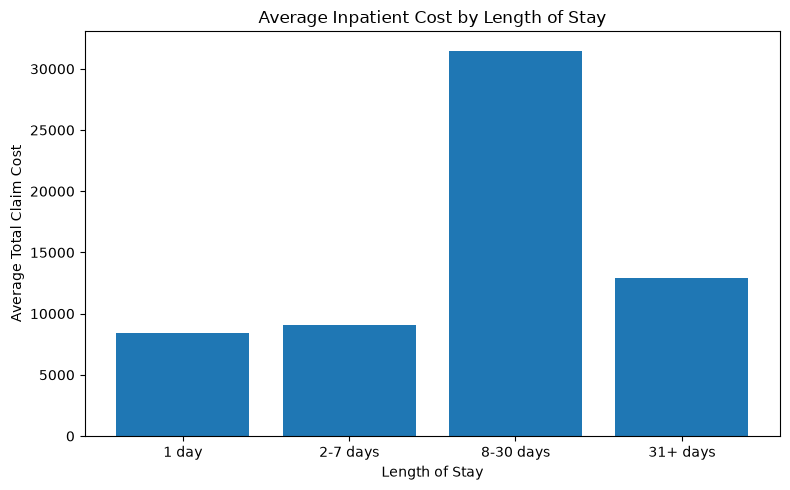

In [88]:
# Q10 - Step 4
# Visualize average inpatient cost by length-of-stay group

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    los_cost_summary.index.astype(str),
    los_cost_summary["Average_Cost"]
)

plt.title("Average Inpatient Cost by Length of Stay")
plt.xlabel("Length of Stay")
plt.ylabel("Average Total Claim Cost")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [89]:
# Q11 - Step 1
# Summarize the major potential cost-inefficiency signals

q11_summary = pd.DataFrame({
    "Pattern": [
        "Top 1% high-cost encounters",
        "30-day repeat encounters",
        "Procedure cost vs total claim cost",
        "No-insurance encounter cost",
        "Ambulatory high-cost rate"
    ],
    "Key_Metric": [
        "17.06% of total cost",
        "Average cost = $6,318.59",
        "Correlation = 0.737",
        "Average cost = $7,455.91",
        "High-cost rate = 2.26%"
    ]
})

q11_summary

,Pattern,Key_Metric
0,Top 1% high-cost encounters,17.06% of total cost
1,30-day repeat encounters,"Average cost = $6,318.59"
2,Procedure cost vs total claim cost,Correlation = 0.737
3,No-insurance encounter cost,"Average cost = $7,455.91"
4,Ambulatory high-cost rate,High-cost rate = 2.26%


In [90]:
# Q11 - Step 2
# Add interpretation and potential investigation areas

q11_interpretation = pd.DataFrame({
    "Pattern": [
        "Top 1% high-cost encounters",
        "30-day repeat encounters",
        "Procedure-related cost",
        "No-insurance encounters",
        "Ambulatory high-cost encounters"
    ],
    "Evidence": [
        "Top 1% of encounters account for 17.06% of total recorded cost",
        "Repeat encounters have average cost of $6,318.59 versus $2,875.91 for non-repeat encounters",
        "Procedure cost has a 0.737 correlation with total claim cost",
        "No-insurance encounters have the highest average recorded cost at $7,455.91",
        "Ambulatory encounters have a 2.26% high-cost encounter rate"
    ],
    "Potential_Investigation": [
        "Investigate characteristics of extreme-cost encounters",
        "Examine whether frequent repeat encounters involve avoidable utilization",
        "Investigate high-cost procedures and variation in procedure utilization",
        "Investigate whether payer mix and coverage differences contribute to cost variation",
        "Investigate drivers of high-cost ambulatory encounters"
    ]
})

q11_interpretation

,Pattern,Evidence,Potential_Investigation
0,Top 1% high-cost encounters,Top 1% of encounters account for 17.06% of tot...,Investigate characteristics of extreme-cost en...
1,30-day repeat encounters,"Repeat encounters have average cost of $6,318....",Examine whether frequent repeat encounters inv...
2,Procedure-related cost,Procedure cost has a 0.737 correlation with to...,Investigate high-cost procedures and variation...
3,No-insurance encounters,No-insurance encounters have the highest avera...,Investigate whether payer mix and coverage dif...
4,Ambulatory high-cost encounters,Ambulatory encounters have a 2.26% high-cost e...,Investigate drivers of high-cost ambulatory en...


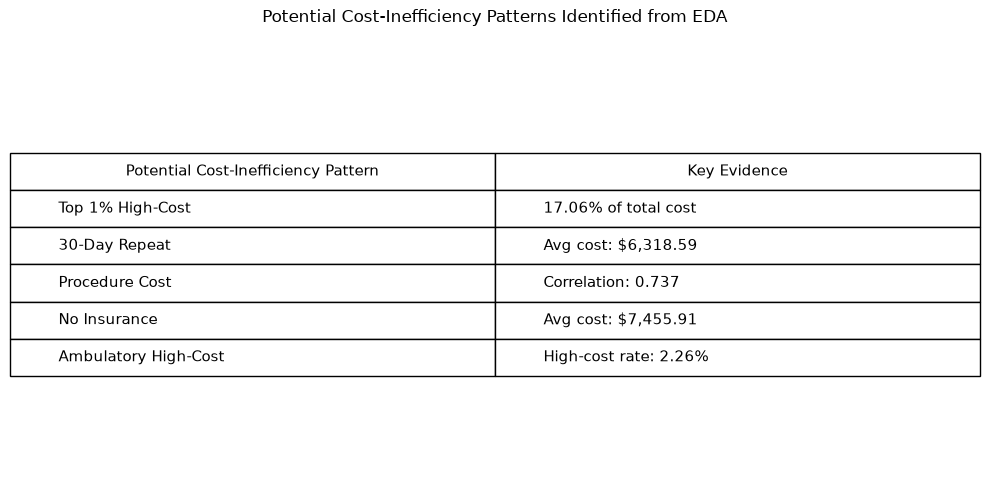

In [91]:
# Q11 - Final Visualization
# Summary of potential cost-inefficiency patterns

import matplotlib.pyplot as plt

patterns = [
    "Top 1% High-Cost",
    "30-Day Repeat",
    "Procedure Cost",
    "No Insurance",
    "Ambulatory High-Cost"
]

evidence = [
    "17.06% of total cost",
    "Avg cost: $6,318.59",
    "Correlation: 0.737",
    "Avg cost: $7,455.91",
    "High-cost rate: 2.26%"
]

fig, ax = plt.subplots(figsize=(10, 5))

ax.axis("off")

table = ax.table(
    cellText=list(zip(patterns, evidence)),
    colLabels=["Potential Cost-Inefficiency Pattern", "Key Evidence"],
    cellLoc="left",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 2)

plt.title(
    "Potential Cost-Inefficiency Patterns Identified from EDA",
    pad=20
)

plt.tight_layout()
plt.show()